# Difference between WGS and Imputed Genotype Data
Whole Genome Sequencing (WGS) and Imputed Genotype Data differ mainly in how genetic variants are obtained:
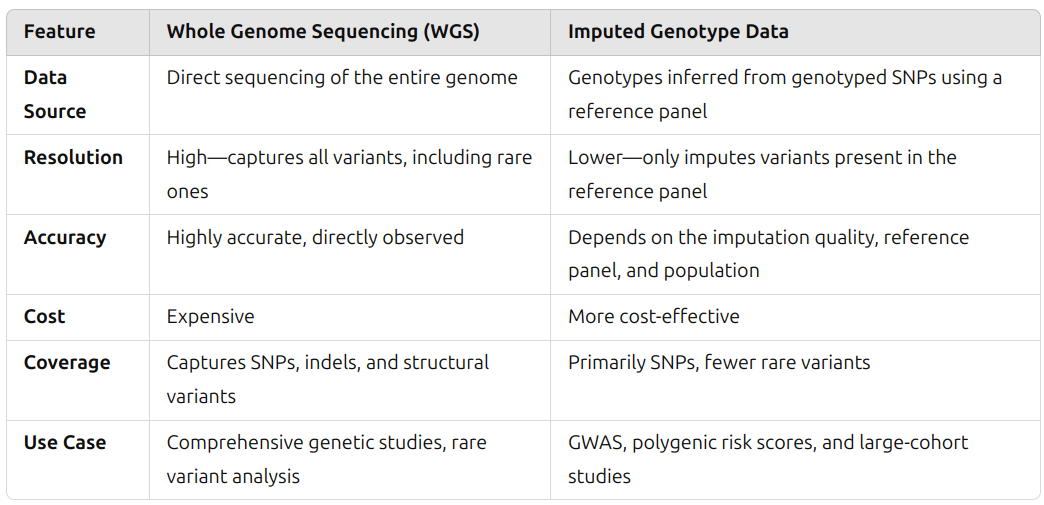
# LD Reference Panel
A Linkage Disequilibrium (LD) reference panel is a dataset of phased genotypes from a population used for imputation, association studies, and fine-mapping. Popular LD reference panels include:

1000 Genomes Project (global, diverse population)
Haplotype Reference Consortium (HRC) (European-focused, large sample size)
TOPMed (high-depth sequencing, diverse ancestry)
UK Biobank (large-scale UK population data)
These panels help in imputation by predicting missing genotypes based on observed SNPs and LD patterns.


# hg38 vs hg19
These refer to different versions of the human genome reference assembly:
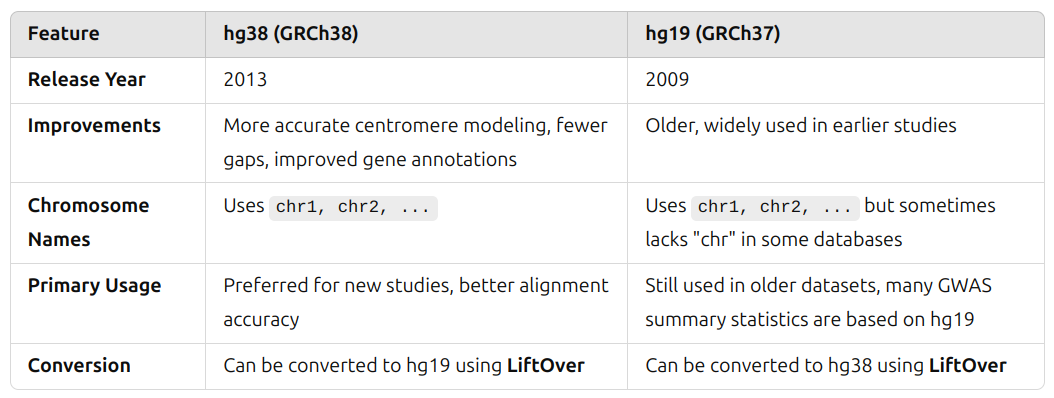
Many LD reference panels (like 1000 Genomes) provide data in both hg19 and hg38, so researchers often convert between the two when performing genetic analyses.

## To check which reference your GWAS statistics/ genotype data is based on, check the position of a variant(usually rsxxxx):
To find the genomic position of an rsID (e.g., rs12345) and determine whether it is based on hg38 or hg19, you can use several approaches:

1. Use dbSNP (NCBI)
* Go to [dbSNP](https://www.ncbi.nlm.nih.gov/snp/?term=rs667647)
* Search for the rsID (e.g., rs12345)
* Check the "Genomic Context" section, which lists positions in GRCh38 (hg38) and GRCh37 (hg19).
2. Use UCSC Genome Browser
* Open [UCSC Genome Browser](https://genome.ucsc.edu/)
* Select "hg38" or "hg19" as the genome assembly.
* Enter the rsID in the search box.
* It will display the exact genomic coordinates.
3. Use Ensembl
* Go to [Ensembl](https://useast.ensembl.org/index.html)
* Search for the rsID.
* It provides genomic positions for different genome assemblies (GRCh38, GRCh37).
4. Use ANNOVAR or LiftOver (If You Need to Convert Coordinates)
If you have coordinates in one genome build and need to convert them:

* LiftOver: Use [UCSC LiftOver](https://genome-euro.ucsc.edu/cgi-bin/hgLiftOver) to convert hg19 ↔ hg38.
* ANNOVAR: Use annotate_variation.pl in ANNOVAR to map rsIDs to different genome builds.
**Note: script for conversion located at: s3://statfungen/ftp_fgc_xqtl/interactive_analysis/rl3328/resource/hg19_to_hg38.sh**

## To retrieve rsID positions from a VCF file using vcftools or bcftools, follow these approaches:
1. Using bcftools
* bcftools query extracts specific fields from a VCF file.
```
bcftools query -f '%CHROM\t%POS\t%ID\n' input.vcf.gz > output_rsids.txt
%CHROM → Chromosome
%POS → Genomic position
%ID → rsID (if available)
input.vcf.gz → Your VCF file (compressed or uncompressed)
output_rsids.txt → Output file with chromosome, position, and rsID
```

* Filter for Specific rsID
To find a specific rsID (e.g., rs12345):
`bcftools view -i 'ID=="rs12345"' input.vcf.gz`

* Extract Positions for All Known rsIDs
`bcftools query -f '%ID\t%CHROM\t%POS\n' input.vcf.gz | grep "rs" > rs_positions.txt`
This filters only the rsIDs and ignores variants without an rsID.
  
2. Using vcftools
To extract only rsIDs and their positions, use:
`vcftools --gzvcf input.vcf.gz --get-INFO ID --out output_rsids`
This will create output_rsids.INFO containing the rsIDs.
If you want a TSV format with chromosome and position:
`vcftools --gzvcf input.vcf.gz --stdout --positions pos_list.txt`
* pos_list.txt should contain:
```
chr1 123456
chr2 7891011
```
* Output will be VCF lines for those positions.




